<a href="https://colab.research.google.com/github/mainapkago-pixel/course-project-GitHub-/blob/main/Paul_maina_Week_6_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data prepared and scaled successfully for clustering!
Shape of scaled data: (30, 8)
Sample of encoded features:
   PMS Price (KES/L)  AGO Price (KES/L)  Tank Condition  Fire Extinguishers  \
0              185.5              172.3             1.0                   1   
1              184.8              171.9             1.0                   1   
2              186.2              173.1             1.0                   1   
3              183.7              170.8             1.0                   1   
4              184.9              172.0             0.0                   1   

   Drainage  Earthing  Spill Kit  Compliant  
0         1         1          1          1  
1         1         1          1          1  
2         0         1          1          0  
3         1         1          1          1  
4         1         0          1          0  


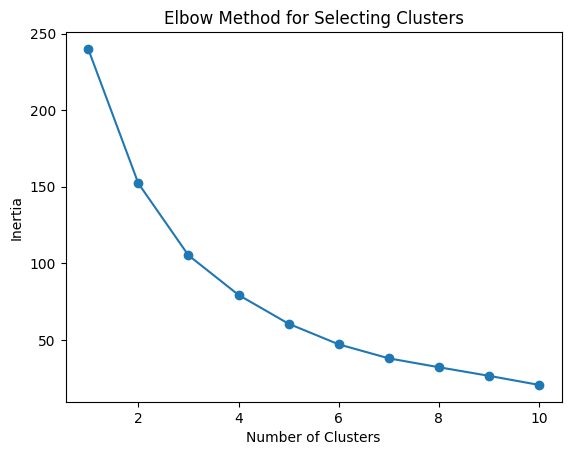

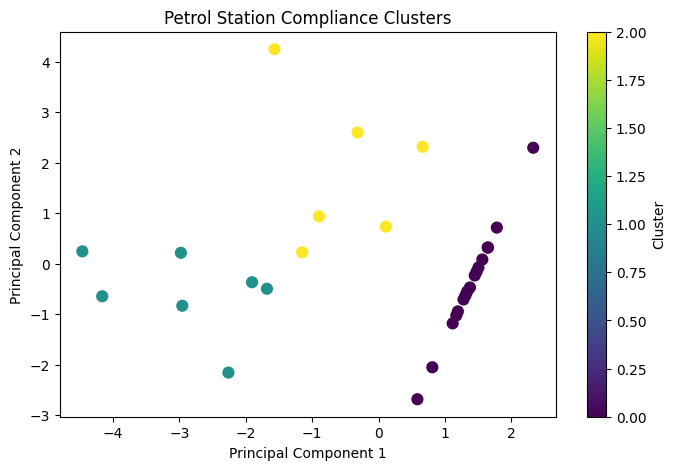

   Cluster  PMS Price (KES/L)  AGO Price (KES/L) Tank Condition  \
0        0              185.5              172.3           Good   
1        0              184.8              171.9           Good   
2        2              186.2              173.1           Good   
3        0              183.7              170.8           Good   
4        1              184.9              172.0           Fair   
5        0              185.6              171.7           Good   
6        2              185.2              172.1           Good   
7        1              184.6              171.5           Fair   
8        0              186.0              172.8           Good   
9        0              185.4              172.2           Good   

  Fire Extinguishers Drainage Earthing Spill Kit Compliant  
0                Yes      Yes      Yes       Yes       Yes  
1                Yes      Yes      Yes       Yes       Yes  
2                Yes       No      Yes       Yes        No  
3                Y

In [16]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Load the CSV dataset
df = pd.read_csv('/content/stations data.csv')

# Features useful for clustering
features = [
    'PMS Price (KES/L)',
    'AGO Price (KES/L)',
    'Tank Condition',
    'Fire Extinguishers',
    'Drainage',
    'Earthing',
    'Spill Kit',
    'Compliant'
]

# Subset the dataset
X = df[features].copy()

# Map binary/categorical values (Yes/No, Good/Bad, etc.) to numerical values
for col in X.columns:
    if X[col].dtype == 'object':
        # Map common Yes/No, Good/Bad, Compliant/Non-Compliant values to 1/0
        X[col] = X[col].astype(str).str.strip().str.lower().map({
            'yes': 1, 'no': 0,
            'good': 1, 'bad': 0,
            'compliant': 1, 'non-compliant': 0
        }).fillna(0)

# Handle any numerical missing values by replacing them with the median
X = X.fillna(X.median())

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data prepared and scaled successfully for clustering!")
print("Shape of scaled data:", X_scaled.shape)
print("Sample of encoded features:")
print(X.head())


from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Calculate inertia for different numbers of clusters
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

# Plot the Elbow Method graph
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Selecting Clusters')
plt.show()

from sklearn.decomposition import PCA

# Apply K-Means with three clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
df['Cluster'] = clusters
X['Cluster'] = clusters

# Reduce the features to two dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['Cluster'],
    cmap='viridis',
    s=60
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Petrol Station Compliance Clusters')
plt.colorbar(label='Cluster')
plt.show()

# Display the cluster assignments
print(df[['Cluster'] + features].head(10))


# Calculate average feature values for each cluster using the numeric X DataFrame
cluster_summary = X.groupby('Cluster').mean()

print("\nAverage compliance characteristics by cluster (binary metrics: 1=Yes/Good, 0=No/Bad):")
print(cluster_summary.round(2))

1. Markdown cell: Select the features
Selecting Features for Clustering
I will use the following features to group petrol stations based on their compliance with Kenyan petroleum standards:
- Safety Compliance
- Fire Safety
- Environmental Compliance
- Equipment Compliance
- Overall Compliance Score
These features will help identify stations with similar levels of compliance and safety performance.
2. Code cell: Prepare the data
This code assumes your CSV file contains the five features listed above. If your column names differ, replace them with the actual names in your dataset.
3. Markdown cell: Apply a clustering algorithm
Applying K-Means Clustering
I will use the K-Means clustering algorithm to group petrol stations with similar compliance characteristics. K-Means assigns stations to clusters based on similarities in their selected features. I will test different numbers of clusters to determine the most suitable grouping.
4. Explore different numbers of clusters
Look for the point on the graph where the decrease in inertia starts slowing down. This is called the elbow, and it helps you choose a suitable number of clusters. Three clusters may be a useful starting point, but use the graph to guide your decision.
5. Code cell: Train the model and plot the clusters
The following code uses three clusters as an example. Change n_clusters=3 if your Elbow Method graph suggests another number.
###  Results

The K-Means model groups petrol stations according to similarities in their safety, fire safety, environmental, equipment, and overall compliance scores. Stations in clusters with higher average scores may represent stations that comply with more of the selected requirements. Clusters with lower average scores may represent stations requiring corrective action, while intermediate clusters may represent stations with partial compliance.

The Elbow Method helps identify an appropriate number of clusters, and the scatter plot provides a visual representation of the groups. These findings can help prioritize inspections and identify areas requiring improvement. However, the clusters do not automatically determine legal compliance; each station must still be assessed against the applicable Kenyan standards.